# Tarefa 1 — Classificação de triagem START: CART e MLP

Comparamos três configurações de cada classificador usando **F1 macro** e cinco
folds estratificados. U, E e O representam subajuste, equilíbrio e sobreajuste
observados nos resultados, e não garantias associadas a um hiperparâmetro.

**Referência dos dados:** o `src/gerar_dados_vitimas.py` é a versão atual.
Sua função possui os padrões: 2.500 vítimas iniciais por classe (10.000 no total),
idade média 35, desvio da idade 15, ruído 0,02 e semente 42. Ela **não recebe
`tipo_acidente`**. O bloco de execução direta do arquivo usa outros parâmetros e
gera 1.300 vítimas; ele não será executado aqui. Um dataset gerado localmente não
substitui o teste cego fornecido pelo professor.

Abra este notebook com a pasta do projeto como diretório de trabalho e selecione
o Python de `.venv`. Dependências, caso precise preparar outro ambiente:

```bash
python -m pip install -r requirements.txt
```

O notebook salva os resultados executados nas saídas das células. Os modelos
finais são treinados com todas as 10.000 amostras. O teste cego está configurado para `dados/teste/data.csv`, com 1.300 vítimas, na seção 14.

## 1. Imports

Usamos os classificadores e as ferramentas de validação do scikit-learn.
O gerador é importado como módulo, sem executar seu bloco `__main__`.

In [1]:
from pathlib import Path
from inspect import signature
from importlib.metadata import version
import hashlib
import random
import subprocess
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    precision_score, recall_score, f1_score, accuracy_score,
    ConfusionMatrixDisplay,
)
from threadpoolctl import threadpool_limits

from src import gerar_dados_vitimas as gerador

%matplotlib inline

## 2. Configurações gerais e reprodutibilidade

Lemos os parâmetros padrão diretamente da função atual, em vez de copiar
parâmetros de uma versão antiga. Registramos também as versões das bibliotecas.

In [2]:
SEED = 42
N_FOLDS = 5
BASE = Path.cwd()
CAMINHO_TREINO = BASE / "dados" / "treino" / "data_ruido_avpu_tri.csv"
PASTA_MODELOS = BASE / "modelos" / "classificador"
CLASSES = [0, 1, 2, 3]
NOMES_CLASSES = ["Verde", "Amarelo", "Vermelho", "Preto"]
ROTULOS_MATRIZ = ["G (verde)", "Y (amarelo)", "R (vermelho)", "B (preto)"]

np.random.seed(SEED)
random.seed(SEED)
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:.6f}".format)

config_geracao = {
    nome: parametro.default
    for nome, parametro in signature(gerador.gerar_dataset_vitimas).parameters.items()
}
assert sum(config_geracao["distrib_tri"].values()) == 10_000
assert config_geracao["seed"] == SEED
display(pd.Series(config_geracao, name="Padrões do gerador atual").to_frame())

versoes = pd.Series({
    "Python": sys.version.split()[0],
    **{pacote: version(pacote) for pacote in (
        "numpy", "pandas", "scikit-learn", "matplotlib", "joblib"
    )},
}, name="Versão")
display(versoes.to_frame())

,Padrões do gerador atual
distrib_tri,"{0: 2500, 1: 2500, 2: 2500, 3: 2500}"
media_idade,35
desvio_idade,15
nivel_ruido,0.020000
seed,42


,Versão
Python,3.12.14
numpy,2.5.3
pandas,3.0.6
scikit-learn,1.9.1
matplotlib,3.11.2
joblib,1.6.0


## 3. Geração e carregamento do dataset de treino

Se o CSV ainda não existir, chamamos a função do gerador **sem alterar seus
padrões**. Redirecionamos somente o arquivo de saída para o nome pedido na tarefa.
A chamada roda em outro processo com backend gráfico `Agg`, para evitar exibir o
histograma que faz parte do gerador. A lógica de geração permanece intacta.

Se o CSV já existir, ele será reutilizado. Os parâmetros registrados descrevem
a geração configurada neste notebook; confirme a origem de um CSV trazido de
outro experimento, pois ruído e parâmetros de geração não são inferíveis do CSV.

In [3]:
csv_gerado_agora = not CAMINHO_TREINO.exists()
if csv_gerado_agora:
    codigo_geracao = """
import matplotlib
matplotlib.use("Agg")
from pathlib import Path
from src import gerar_dados_vitimas as gerador
gerador.OUTPUT_CSV = Path("dados/treino/data_ruido_avpu_tri.csv")
gerador.gerar_dataset_vitimas()
"""
    execucao = subprocess.run(
        [sys.executable, "-c", codigo_geracao],
        cwd=BASE, check=True, capture_output=True, text=True,
    )
    print(execucao.stdout)
else:
    print(f"CSV de treinamento reutilizado: {CAMINHO_TREINO.name}")

df = pd.read_csv(CAMINHO_TREINO)
assert len(df) == 10_000, "O treinamento desta tarefa exige 10.000 amostras."
hash_dataset = hashlib.sha256(CAMINHO_TREINO.read_bytes()).hexdigest()
hash_gerador = hashlib.sha256(Path(gerador.__file__).read_bytes()).hexdigest()

CSV de treinamento reutilizado: data_ruido_avpu_tri.csv


## 4. Inspeção inicial

Mostramos apenas a estrutura, a distribuição das quatro classes e as estatísticas
de idade necessárias ao relatório. O desvio padrão amostral usa `ddof=1`.

In [4]:
display(df.head())
print("Dimensões:", df.shape)
print("Colunas:", df.columns.tolist())

assert df["tri"].isin(CLASSES).all(), "Há classes de triagem inválidas."
contagem_classes = df["tri"].value_counts().reindex(CLASSES, fill_value=0)
distribuicao_classes = pd.DataFrame({
    "Classe": CLASSES,
    "Triagem": NOMES_CLASSES,
    "Vítimas": contagem_classes.to_numpy(),
})
media_idade = df["idade"].mean()
dpa_idade = df["idade"].std(ddof=1)
display(distribuicao_classes)
display(pd.Series({
    "Média da idade": media_idade,
    "DPA da idade (ddof=1)": dpa_idade,
}, name="Idade").to_frame())

,idade,fc,fr,pas,spo2,temp,pr,sg,fx,queim,gcs,avpu,tri,sobr
0,42,105,21,90,94,35.500000,1,2,0,0,12,1,1,0.770000
1,32,122,12,66,86,32.400000,0,1,0,3,7,3,2,0.380000
2,44,122,8,162,86,38.500000,1,1,0,2,11,2,2,0.720000
3,57,68,13,121,99,36.800000,1,0,0,0,14,1,0,0.950000
4,31,85,25,89,92,38.200000,1,2,1,1,11,2,1,0.670000


Dimensões: (10000, 14)
Colunas: ['idade', 'fc', 'fr', 'pas', 'spo2', 'temp', 'pr', 'sg', 'fx', 'queim', 'gcs', 'avpu', 'tri', 'sobr']


,Classe,Triagem,Vítimas
0,0,Verde,2478
1,1,Amarelo,2516
2,2,Vermelho,2534
3,3,Preto,2472


,Idade
Média da idade,34.541600
DPA da idade (ddof=1),14.869720


## 5. Definição de X e y

Selecionamos explicitamente as dez entradas permitidas. `gcs`, `avpu`, `sobr` e
o próprio alvo `tri` ficam fora de X.

In [5]:
features = [
    "idade", "fc", "fr", "pas", "spo2", "temp", "pr", "sg", "fx", "queim"
]
X = df[features]
y = df["tri"]

assert X.columns.tolist() == features and X.shape == (10_000, 10)
assert set(X.columns).isdisjoint({"gcs", "avpu", "tri", "sobr"})
assert np.isfinite(X.to_numpy(dtype=float)).all(), "Há entradas ausentes ou infinitas."
print("Entradas:", X.columns.tolist())
print("Alvo:", y.name)

Entradas: ['idade', 'fc', 'fr', 'pas', 'spo2', 'temp', 'pr', 'sg', 'fx', 'queim']
Alvo: tri


## 6. Validação cruzada estratificada

Todos os seis experimentos usam os mesmos cinco folds, com embaralhamento e
semente 42. O teste cego não participa desta etapa.

In [6]:
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
assert contagem_classes.min() >= N_FOLDS
print(f"Validação: {N_FOLDS} folds estratificados; random_state={SEED}")

Validação: 5 folds estratificados; random_state=42


## 7. Função auxiliar de avaliação

`cross_validate` calcula o F1 macro de treino e validação em cada fold. Calculamos
primeiro as **diferenças absolutas por fold**, depois sua média e DPA. Não usamos
a diferença entre médias como substituta. Todos os DPAs usam `ddof=1`.

Registramos o número de iterações das MLPs para conferir o treinamento. Os avisos
de convergência permanecem visíveis. Limitamos o cálculo numérico a uma thread
para evitar excesso de threads em redes pequenas; isso não altera os folds.

In [7]:
def avaliar_modelo(modelo, X, y, cv):
    with threadpool_limits(limits=1):
        scores = cross_validate(
            modelo, X, y, cv=cv, scoring="f1_macro",
            return_train_score=True, return_estimator=True,
            n_jobs=1, error_score="raise",
        )

    f1_treino = scores["train_score"]
    f1_validacao = scores["test_score"]
    diferencas = np.abs(f1_treino - f1_validacao)
    folds = pd.DataFrame({
        "Treino": f1_treino,
        "Validação": f1_validacao,
        "Diferença": diferencas,
    }, index=pd.Index(range(1, cv.n_splits + 1), name="Fold"))
    resumo = pd.DataFrame({
        "Média": folds.mean(),
        "DPA": folds.std(ddof=1),
    })

    iteracoes = None
    if isinstance(modelo, Pipeline):
        iteracoes = [
            estimador.named_steps["mlp"].n_iter_
            for estimador in scores["estimator"]
        ]
    return {"folds": folds, "resumo": resumo, "iteracoes": iteracoes}


def tabela_media_dpa(resultados):
    tabela = pd.DataFrame(index=["Treino", "Validação", "Diferença"])
    for nome, resultado in resultados.items():
        resumo = resultado["resumo"]
        tabela[nome] = [
            f"{resumo.loc[metrica, 'Média']:.6f} ({resumo.loc[metrica, 'DPA']:.6f})"
            for metrica in tabela.index
        ]
    return tabela

## 8. CART U, E e O

U permite uma única divisão e restringe a capacidade da árvore. E limita a
profundidade e exige ao menos dez amostras por folha. O permite crescimento livre
e folhas com uma amostra, favorecendo a memorização do ruído.

In [8]:
config_cart = {
    "CART U": {"max_depth": 1, "min_samples_leaf": 100, "criterion": "gini"},
    "CART E": {"max_depth": 6, "min_samples_leaf": 10, "criterion": "gini"},
    "CART O": {"max_depth": None, "min_samples_leaf": 1, "criterion": "gini"},
}
modelos_cart = {
    nome: DecisionTreeClassifier(**parametros, random_state=SEED)
    for nome, parametros in config_cart.items()
}
display(pd.DataFrame(config_cart).T)

resultados_cart = {}
for nome, modelo in modelos_cart.items():
    print(f"Avaliando {nome}...")
    resultados_cart[nome] = avaliar_modelo(modelo, X, y, cv)
    display(resultados_cart[nome]["folds"])

,max_depth,min_samples_leaf,criterion
CART U,1,100,gini
CART E,6,10,gini
CART O,None,1,gini


Avaliando CART U...


,Treino,Validação,Diferença
Fold,,,
1,0.364620,0.362953,0.001668
2,0.364386,0.363893,0.000493
3,0.363823,0.366149,0.002326
4,0.364609,0.363008,0.001601
5,0.363995,0.365473,0.001477


Avaliando CART E...


,Treino,Validação,Diferença
Fold,,,
1,0.975674,0.969521,0.006153
2,0.969816,0.963216,0.006600
3,0.968874,0.968057,0.000817
4,0.975047,0.972055,0.002992
5,0.968719,0.970129,0.001409


Avaliando CART O...


,Treino,Validação,Diferença
Fold,,,
1,1.000000,0.956056,0.043944
2,1.000000,0.945715,0.054285
3,1.000000,0.956053,0.043947
4,1.000000,0.943689,0.056311
5,1.000000,0.951149,0.048851


## 9. Comparação CART

Cada célula da tabela contém **média (DPA)** do F1 macro ou da diferença absoluta.
Compare os valores calculados para verificar subajuste, equilíbrio e sobreajuste.

In [9]:
tabela_cart = tabela_media_dpa(resultados_cart)
display(tabela_cart)

,CART U,CART E,CART O
Treino,0.364287 (0.000362),0.971626 (0.003442),1.000000 (0.000000)
Validação,0.364295 (0.001453),0.968595 (0.003332),0.950532 (0.005731)
Diferença,0.001513 (0.000658),0.003594 (0.002666),0.049468 (0.005731)


## 10. Rede neural MLP U, E e O

Cada rede está em um `Pipeline(StandardScaler + MLPClassifier)`: a escala é
aprendida somente com o treino de cada fold. O parâmetro `alpha` controla a
regularização L2. U tem uma camada muito pequena, ativação `tanh`, taxa inicial
menor e regularização forte; E tem duas camadas intermediárias e ativação `relu`;
O tem três camadas maiores e regularização mínima.

As redes usam Adam; sua taxa inicial é `learning_rate_init`. `early_stopping=False`
permite usar todas as amostras de treino do fold e, no ajuste final, as 10.000
amostras. O treinamento pode parar antes de `max_iter` quando a perda deixa de
melhorar segundo `tol` e `n_iter_no_change`; não reduzimos artificialmente
`max_iter` para produzir o subajuste.

In [10]:
config_rn = {
    "RN U": {
        "hidden_layer_sizes": (2,), "activation": "tanh", "solver": "adam",
        "alpha": 100.0, "learning_rate_init": 0.0005,
        "max_iter": 1500, "tol": 1e-4, "n_iter_no_change": 30,
    },
    "RN E": {
        "hidden_layer_sizes": (32, 16), "activation": "relu", "solver": "adam",
        "alpha": 1.0, "learning_rate_init": 0.001,
        "max_iter": 1000, "tol": 1e-4, "n_iter_no_change": 30,
    },
    "RN O": {
        "hidden_layer_sizes": (128, 128, 64), "activation": "relu", "solver": "adam",
        "alpha": 1e-6, "learning_rate_init": 0.001,
        "max_iter": 1500, "tol": 1e-5, "n_iter_no_change": 40,
    },
}
modelos_rn = {
    nome: Pipeline([
        ("scaler", StandardScaler()),
        ("mlp", MLPClassifier(**parametros, early_stopping=False, random_state=SEED)),
    ])
    for nome, parametros in config_rn.items()
}
display(pd.DataFrame(config_rn).T)

resultados_rn = {}
for nome, modelo in modelos_rn.items():
    print(f"Avaliando {nome}...")
    resultados_rn[nome] = avaliar_modelo(modelo, X, y, cv)
    display(resultados_rn[nome]["folds"])
    print("Iterações por fold:", resultados_rn[nome]["iteracoes"])

,hidden_layer_sizes,activation,solver,alpha,learning_rate_init,max_iter,tol,n_iter_no_change
RN U,"(2,)",tanh,adam,100.000000,0.000500,1500,0.000100,30
RN E,"(32, 16)",relu,adam,1.000000,0.001000,1000,0.000100,30
RN O,"(128, 128, 64)",relu,adam,0.000001,0.001000,1500,0.000010,40


Avaliando RN U...


,Treino,Validação,Diferença
Fold,,,
1,0.502980,0.504712,0.001732
2,0.499836,0.510506,0.010670
3,0.501900,0.492514,0.009386
4,0.501624,0.497729,0.003895
5,0.497771,0.502320,0.004549


Iterações por fold: [114, 114, 113, 114, 113]
Avaliando RN E...


,Treino,Validação,Diferença
Fold,,,
1,0.980394,0.977505,0.002889
2,0.980388,0.977513,0.002876
3,0.979893,0.979502,0.000391
4,0.978639,0.982010,0.003370
5,0.978261,0.979532,0.001271


Iterações por fold: [369, 332, 408, 382, 302]
Avaliando RN O...


,Treino,Validação,Diferença
Fold,,,
1,0.996120,0.970016,0.026103
2,1.000000,0.966549,0.033451
3,0.995247,0.969971,0.025276
4,0.994247,0.972531,0.021716
5,0.999124,0.965566,0.033559


Iterações por fold: [386, 986, 509, 290, 922]


## 11. Comparação MLP

Os comportamentos U/E/O são sustentados pelas métricas, e não apenas pelo tamanho
da rede. A rede maior deve apresentar treino superior e uma distância maior
entre treino e validação. Essas configurações foram escolhidas por ajustes
manuais pequenos na validação cruzada, sem usar o teste cego.

In [11]:
tabela_rn = tabela_media_dpa(resultados_rn)
display(tabela_rn)
display(pd.DataFrame({
    nome: resultado["iteracoes"] for nome, resultado in resultados_rn.items()
}, index=pd.Index(range(1, N_FOLDS + 1), name="Fold")))

,RN U,RN E,RN O
Treino,0.500822 (0.002046),0.979515 (0.001002),0.996948 (0.002496)
Validação,0.501556 (0.006838),0.979212 (0.001858),0.968927 (0.002838)
Diferença,0.006047 (0.003808),0.002159 (0.001268),0.028021 (0.005271)


,RN U,RN E,RN O
Fold,,,
1,114,369,386
2,114,332,986
3,113,408,509
4,114,382,290
5,113,302,922


## 12. Escolha: melhor CART × melhor MLP

A ordenação prioriza a média do **F1 macro de validação** e usa a menor diferença
absoluta média para desempatar. A tabela também mostra os DPAs e o contraste de
generalização. F1 de treino isolado não é critério de escolha.

Os resultados da validação orientam a seleção e os pequenos ajustes manuais;
portanto não substituem a avaliação independente no teste cego.

In [12]:
todos_resultados = {**resultados_cart, **resultados_rn}
comparacao = pd.DataFrame({
    nome: {
        "Treino média": resultado["resumo"].loc["Treino", "Média"],
        "Treino DPA": resultado["resumo"].loc["Treino", "DPA"],
        "Validação média": resultado["resumo"].loc["Validação", "Média"],
        "Validação DPA": resultado["resumo"].loc["Validação", "DPA"],
        "Diferença média": resultado["resumo"].loc["Diferença", "Média"],
        "Diferença DPA": resultado["resumo"].loc["Diferença", "DPA"],
    }
    for nome, resultado in todos_resultados.items()
}).T
comparacao = comparacao.sort_values(
    ["Validação média", "Diferença média"], ascending=[False, True]
)
display(comparacao)

nome_melhor_cart = comparacao.loc[list(modelos_cart)].sort_values(
    ["Validação média", "Diferença média"], ascending=[False, True]
).index[0]
nome_melhor_rn = comparacao.loc[list(modelos_rn)].sort_values(
    ["Validação média", "Diferença média"], ascending=[False, True]
).index[0]

tabela_melhores = tabela_media_dpa({
    f"Melhor CART ({nome_melhor_cart})": resultados_cart[nome_melhor_cart],
    f"Melhor RN ({nome_melhor_rn})": resultados_rn[nome_melhor_rn],
})
display(tabela_melhores)
print("Melhor CART:", nome_melhor_cart, config_cart[nome_melhor_cart])
print("Melhor RN:", nome_melhor_rn, config_rn[nome_melhor_rn])

,Treino média,Treino DPA,Validação média,Validação DPA,Diferença média,Diferença DPA
RN E,0.979515,0.001002,0.979212,0.001858,0.002159,0.001268
RN O,0.996948,0.002496,0.968927,0.002838,0.028021,0.005271
CART E,0.971626,0.003442,0.968595,0.003332,0.003594,0.002666
CART O,1.000000,0.000000,0.950532,0.005731,0.049468,0.005731
RN U,0.500822,0.002046,0.501556,0.006838,0.006047,0.003808
CART U,0.364287,0.000362,0.364295,0.001453,0.001513,0.000658


,Melhor CART (CART E),Melhor RN (RN E)
Treino,0.971626 (0.003442),0.979515 (0.001002)
Validação,0.968595 (0.003332),0.979212 (0.001858)
Diferença,0.003594 (0.002666),0.002159 (0.001268)


Melhor CART: CART E {'max_depth': 6, 'min_samples_leaf': 10, 'criterion': 'gini'}
Melhor RN: RN E {'hidden_layer_sizes': (32, 16), 'activation': 'relu', 'solver': 'adam', 'alpha': 1.0, 'learning_rate_init': 0.001, 'max_iter': 1000, 'tol': 0.0001, 'n_iter_no_change': 30}


## 13. Retreinamento definitivo com as 10.000 amostras

`clone` cria estimadores novos com os hiperparâmetros selecionados. Ajustamos
ambos com X e y completos, sem outra divisão dos dados nem nova validação cruzada.
O teste cego ainda não foi lido.

In [13]:
melhor_cart = clone(modelos_cart[nome_melhor_cart])
melhor_rn = clone(modelos_rn[nome_melhor_rn])
with threadpool_limits(limits=1):
    melhor_cart.fit(X, y)
    melhor_rn.fit(X, y)

assert int(melhor_cart.tree_.n_node_samples[0]) == len(X)
assert np.all(np.asarray(melhor_rn.named_steps["scaler"].n_samples_seen_) == len(X))
print("Modelos finais ajustados com", len(X), "amostras.")
print("Iterações da MLP final:", melhor_rn.named_steps["mlp"].n_iter_)

Modelos finais ajustados com 10000 amostras.
Iterações da MLP final: 312


## 14. TESTE CEGO

O teste cego está configurado para o arquivo `dados/teste/data.csv`, com 1.300 vítimas.
Se o caminho for `None` ou o arquivo estiver ausente, esta seção ficará pendente
e o notebook continuará normalmente.

Execute a avaliação somente após finalizar todas as escolhas de modelos e
hiperparâmetros, **uma única vez**. Não ajuste os modelos com base nos resultados
do teste cego. A célula preserva as previsões em novas execuções na mesma sessão.
Não substitua esse arquivo por vítimas geradas localmente ou por uma divisão
das 10.000 amostras de treinamento.

In [14]:
CAMINHO_TESTE_CEGO = BASE / "dados" / "teste" / "data.csv"  # Arquivo do teste cego

if "teste_cego_executado" not in globals():
    teste_cego_executado = False

if teste_cego_executado:
    print("Teste cego já avaliado nesta sessão; previsões anteriores preservadas.")
elif CAMINHO_TESTE_CEGO is None:
    print("TESTE CEGO PENDENTE: informe o caminho do arquivo real do professor.")
else:
    caminho_cego = Path(CAMINHO_TESTE_CEGO).expanduser().resolve()
    if not caminho_cego.is_file():
        print(f"TESTE CEGO PENDENTE: arquivo não encontrado: {caminho_cego}")
    else:
        if caminho_cego == CAMINHO_TREINO.resolve():
            raise ValueError("O CSV de treino não pode ser usado como teste cego.")
        df_teste = pd.read_csv(caminho_cego)
        faltantes = set(features + ["tri"]) - set(df_teste.columns)
        if faltantes:
            raise ValueError(f"Colunas ausentes no teste cego: {sorted(faltantes)}")
        if df_teste.empty or not df_teste["tri"].isin(CLASSES).all():
            raise ValueError("O teste cego está vazio ou contém classes inválidas.")

        X_test = df_teste[features]
        y_test = df_teste["tri"]
        if not np.isfinite(X_test.to_numpy(dtype=float)).all():
            raise ValueError("O teste cego contém entradas ausentes ou infinitas.")
        y_pred_cart = melhor_cart.predict(X_test)
        y_pred_rn = melhor_rn.predict(X_test)
        teste_cego_executado = True
        print(f"Teste cego avaliado: {len(df_teste)} vítimas.")

Teste cego avaliado: 1300 vítimas.


## 15. Métricas finais no teste cego

Calculamos precisão, recall e F1 macro com a ordem de classes 0, 1, 2 e 3, além
da acurácia. `zero_division=0` atribui zero quando uma classe não tem previsões
ou amostras suficientes para definir uma razão.

In [15]:
tabela_teste_cego = None
if teste_cego_executado:
    metricas_teste = {}
    for nome, predicoes in {
        "Melhor CART": y_pred_cart, "Melhor RN": y_pred_rn
    }.items():
        metricas_teste[nome] = {
            "Precisão macro": precision_score(
                y_test, predicoes, labels=CLASSES, average="macro", zero_division=0
            ),
            "Recall macro": recall_score(
                y_test, predicoes, labels=CLASSES, average="macro", zero_division=0
            ),
            "F1 macro": f1_score(
                y_test, predicoes, labels=CLASSES, average="macro", zero_division=0
            ),
            "Acurácia": accuracy_score(y_test, predicoes),
        }
    tabela_teste_cego = pd.DataFrame(metricas_teste)
    display(tabela_teste_cego)
else:
    print("Métricas pendentes: nenhum teste cego real foi avaliado.")

,Melhor CART,Melhor RN
Precisão macro,0.888432,0.924485
Recall macro,0.880941,0.928194
F1 macro,0.883946,0.926160
Acurácia,0.883846,0.934615


## 16. Matrizes de confusão

Geramos uma figura para cada melhor modelo, apenas quando o teste cego real
estiver disponível. As linhas representam a classe **real** e as colunas a
classe **predita**, na ordem G, Y, R e B.

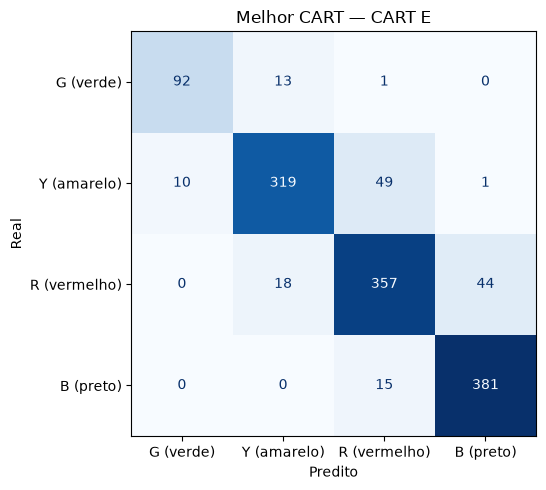

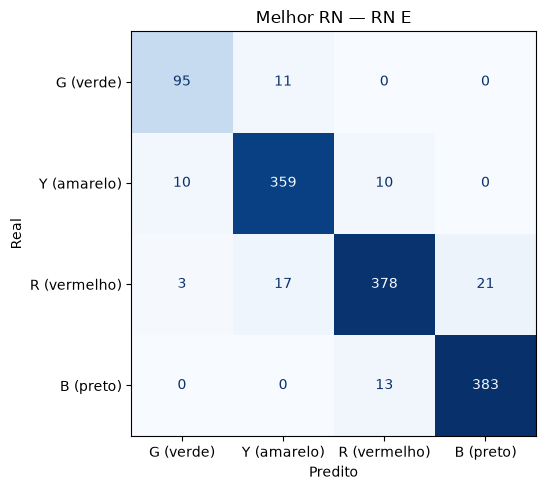

In [16]:
if teste_cego_executado:
    for nome, predicoes in {
        f"Melhor CART — {nome_melhor_cart}": y_pred_cart,
        f"Melhor RN — {nome_melhor_rn}": y_pred_rn,
    }.items():
        fig, ax = plt.subplots(figsize=(7, 5))
        ConfusionMatrixDisplay.from_predictions(
            y_test, predicoes, labels=CLASSES, display_labels=ROTULOS_MATRIZ,
            cmap="Blues", values_format="d", colorbar=False, ax=ax,
        )
        ax.set_title(nome)
        ax.set_xlabel("Predito")
        ax.set_ylabel("Real")
        fig.tight_layout()
        plt.show()
else:
    print("Matrizes pendentes: aguardando o teste cego real.")

## 17. Salvamento dos modelos

Salvamos a árvore e o **Pipeline completo** da MLP, incluindo o scaler ajustado.
Os arquivos são produzidos em `modelos/classificador/`, mesmo enquanto o teste cego estiver pendente.

In [17]:
PASTA_MODELOS.mkdir(parents=True, exist_ok=True)
joblib.dump(melhor_cart, PASTA_MODELOS / "melhor_cart.joblib")
joblib.dump(melhor_rn, PASTA_MODELOS / "melhor_rn.joblib")
print("Modelos salvos em:", PASTA_MODELOS.relative_to(BASE))

Modelos salvos: melhor_cart.joblib e melhor_rn.joblib


## 18. Valores finais para preencher o relatório

Reunimos os valores já calculados, sem repetir treinamentos. As tabelas de
desempenho usam média (DPA). A distribuição final de classes pode diferir da
distribuição inicial de 2.500 por classe devido ao ruído de triagem.

In [18]:
dados_relatorio = pd.Series({
    **{f"Vítimas {nome.lower()}": int(contagem_classes.loc[classe])
       for classe, nome in zip(CLASSES, NOMES_CLASSES)},
    "Total de vítimas": len(df),
    "Média da idade (observada)": media_idade,
    "DPA da idade (observado, ddof=1)": dpa_idade,
    "Média da idade (geração configurada)": config_geracao["media_idade"],
    "Desvio da idade (geração configurada)": config_geracao["desvio_idade"],
    "Ruído (geração configurada)": config_geracao["nivel_ruido"],
    "Tipo de acidente": "Não parametrizado no gerador atual",
    "Semente de geração": config_geracao["seed"],
    "Número de folds": N_FOLDS,
    "Distribuição inicial configurada": str(config_geracao["distrib_tri"]),
    "CSV": str(CAMINHO_TREINO.relative_to(BASE)),
    "SHA-256 do CSV": hash_dataset,
    "SHA-256 do gerador": hash_gerador,
}, name="Valor")

print("DATASET — valores observados e configuração de geração")
display(dados_relatorio.to_frame())
print("CART — hiperparâmetros (random_state=42 em todos)")
display(pd.DataFrame(config_cart).T)
print("CART — F1 macro e diferença: média (DPA)")
display(tabela_cart)
print("REDE NEURAL — hiperparâmetros (random_state=42; early_stopping=False)")
display(pd.DataFrame(config_rn).T)
print("REDE NEURAL — F1 macro e diferença: média (DPA)")
display(tabela_rn)
print("MELHORES:", nome_melhor_cart, "e", nome_melhor_rn)
display(tabela_melhores)
print("TESTE CEGO")
if tabela_teste_cego is not None:
    display(tabela_teste_cego)
else:
    print("Pendente: arquivo real do professor ainda não informado.")

DATASET — valores observados e configuração de geração


,Valor
Vítimas verde,2478
Vítimas amarelo,2516
Vítimas vermelho,2534
Vítimas preto,2472
Total de vítimas,10000
Média da idade (observada),34.541600
"DPA da idade (observado, ddof=1)",14.869720
Média da idade (geração configurada),35
Desvio da idade (geração configurada),15
Ruído (geração configurada),0.020000


CART — hiperparâmetros (random_state=42 em todos)


,max_depth,min_samples_leaf,criterion
CART U,1,100,gini
CART E,6,10,gini
CART O,None,1,gini


CART — F1 macro e diferença: média (DPA)


...

,RN U,RN E,RN O
Treino,0.500822 (0.002046),0.979515 (0.001002),0.996948 (0.002496)
Validação,0.501556 (0.006838),0.979212 (0.001858),0.968927 (0.002838)
Diferença,0.006047 (0.003808),0.002159 (0.001268),0.028021 (0.005271)


MELHORES: CART E e RN E


,Melhor CART (CART E),Melhor RN (RN E)
Treino,0.971626 (0.003442),0.979515 (0.001002)
Validação,0.968595 (0.003332),0.979212 (0.001858)
Diferença,0.003594 (0.002666),0.002159 (0.001268)


TESTE CEGO


,Melhor CART,Melhor RN
Precisão macro,0.888432,0.924485
Recall macro,0.880941,0.928194
F1 macro,0.883946,0.926160
Acurácia,0.883846,0.934615


### Leitura dos resultados e referências

Observe as seções **8–11** para comparar cada configuração e seus folds, a seção
**12** para a seleção dos melhores modelos e a seção **18** para transcrever os
valores do relatório. Resultados U/E/O descrevem este dataset e estas escolhas;
não significam que uma rede maior sempre generaliza pior.

Documentação oficial: [validação cruzada e `cross_validate`](https://scikit-learn.org/stable/modules/cross_validation.html),
[MLPClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html)
e [redes neurais e padronização](https://scikit-learn.org/stable/modules/neural_networks_supervised.html).